# LicenseWise — Phase 1 Preliminary Results
ENSF 621 · Software Licensing Explainability with LLMs

Contents
1. Setup
2. Data sources & loading
3. Preprocessing summary
4. EDA — Software Heritage license sample (20k files)
5. EDA — License knowledge base & clauses
6. Test data for evaluation
7. Models
8. Evaluation — NLI verifier
9. Evaluation — Stage 1 recommendation
10. Pipeline demo

Every figure is also saved to `docs/figures/` for the slides.

In [1]:
import json, sys, statistics as st
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
DATA = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Validated reference palette (light mode): categorical slots in fixed order.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, SURFACE, INK, INK2 = "#b4b2ac", "#fcfcfb", "#0b0b0b", "#52514e"
SEQ = mcolors.LinearSegmentedColormap.from_list("seq_blue", ["#eef4fc", BLUE, "#0f3d75"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": "#d8d6cf", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def hbar(ax, labels, values, colors, fmt="{:,}", total=None):
    y = range(len(labels))[::-1]
    ax.barh(list(y), values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(list(y), labels)
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values):
        txt = fmt.format(v) + (f"  ({v / total:.0%})" if total else "")
        ax.text(v, yi, "  " + txt, va="center", color=INK2, fontsize=10)
    ax.set_xlim(0, max(values) * 1.28)

## 2. Data sources & loading

| Source | Content | Use |
|---|---|---|
| Software Heritage license dataset (Zenodo 6379164) | 6.5M license files: metadata + 20k-file text sample | EDA, real-world variants |
| choosealicense.com | 47 licenses: permissions / conditions / limitations + full text | Knowledge base, ground truth |
| SPDX License List | 740 IDs, OSI-approved flags | Scope filter, ID normalisation |
| PyPI / npm registries | Declared dependency licenses | Manifest input (live) |

In [2]:
sample = pd.read_csv(DATA / "sample20k_index.csv")
kb_all = json.loads((DATA / "licenses.json").read_text())
kb = [l for l in kb_all if l["in_scope"]]
print(f"sample files: {len(sample):,} | columns: {list(sample.columns)}")
print(f"knowledge base: {len(kb_all)} licenses, {len(kb)} in scope")
sample.head(3)

sample files: 20,000 | columns: ['sha1', 'swhid', 'path', 'filenames', 'mime_type', 'encoding', 'line_count', 'word_count', 'size', 'licenses', 'max_score', 'in_scope_license', 'category', 'occurrences', 'earliest_ts', 'origin_url']
knowledge base: 47 licenses, 34 in scope


,sha1,swhid,path,filenames,mime_type,encoding,line_count,word_count,size,licenses,max_score,in_scope_license,category,occurrences,earliest_ts,origin_url
0,000034cfb8c59bf21e1b6bf3a7d67b1989729158,swh:1:cnt:460bdfeb6eb8916131d3a290195a29e07ebb...,sample20k/00/00/000034cfb8c59bf21e1b6bf3a7d67b...,LICENSE.md,text/plain,us-ascii,21.0,171.0,1087,MIT,100.0,MIT,clean,113.0,1.535828e+09,https://github.com/vtsuperdarn/SD_exodus
1,0000c325f65bdc7380a41ead054b43f3088b6613,swh:1:cnt:be27a0214cbd0bfe9fa7c4660b2039c013c7...,sample20k/00/00/0000c325f65bdc7380a41ead054b43...,LICENSE.md,text/plain,us-ascii,21.0,172.0,1115,MIT,100.0,MIT,clean,25.0,1.535951e+09,https://github.com/rickmacgillis/artisan-tool
2,0001c7f79652b848636a8e6f9aa6191a4494dfa8,swh:1:cnt:296d929f349f1d35b8c244dc32821221e25e...,sample20k/00/01/0001c7f79652b848636a8e6f9aa619...,LICENSE,text/plain,us-ascii,21.0,170.0,1073,MIT,100.0,MIT,clean,74.0,1.467905e+09,https://github.com/algolia/redux-magic-async-m...


## 3. Preprocessing summary

1. **Join** 5 metadata tables (SHA1 ↔ SWHID) into one index for the 20k sample (`scripts/build_sample_index.py`).
2. **Categorise** each file: *clean* (one in-scope license, ScanCode score 100), *variant* (score < 100), *multi* (several licenses), *out_of_scope*, *undetected*.
3. **Scope** the knowledge base: software-only + OSI-approved → 47 → 34 licenses (`scripts/build_license_kb.py`).
4. **Language flag**: CeCILL-2.1 text is French → excluded from NLI verification.
5. **Clause splitting**: merge headings, attach lead-ins to list items, drop non-English (`licensewise/clauses.py`).
6. **Normalise** dependency licenses to SPDX IDs (aliases, classifiers, expressions) (`licensewise/deps.py`).

In [3]:
excluded = [(l["spdx_id"], l["intended_for"] if l["intended_for"] != "software" else "not OSI-approved")
            for l in kb_all if not l["in_scope"]]
pd.DataFrame(excluded, columns=["license", "excluded because"])

,license,excluded because
0,BSD-3-Clause-Clear,not OSI-approved
1,BSD-4-Clause,not OSI-approved
2,CC-BY-4.0,media
3,CC-BY-SA-4.0,media
4,CC0-1.0,not OSI-approved
5,CERN-OHL-P-2.0,hardware
6,CERN-OHL-S-2.0,hardware
7,CERN-OHL-W-2.0,hardware
8,GFDL-1.3,documentation
9,ODbL-1.0,data


## 4. EDA — Software Heritage license sample (20k files)

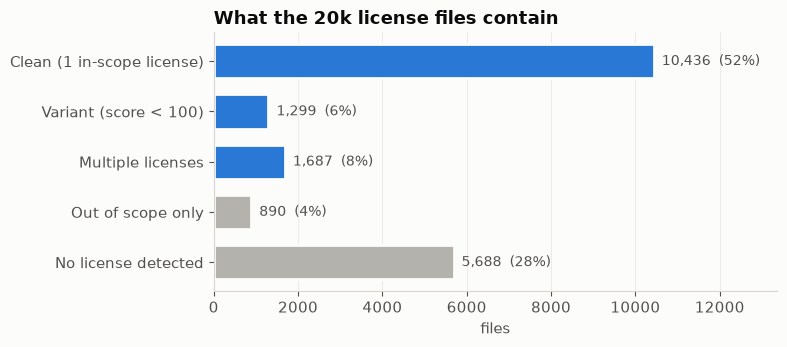

in scope: 13,422 of 14,312 detected files = 93.8%


In [4]:
order = ["clean", "variant", "multi", "out_of_scope", "undetected"]
names = {"clean": "Clean (1 in-scope license)", "variant": "Variant (score < 100)",
         "multi": "Multiple licenses", "out_of_scope": "Out of scope only", "undetected": "No license detected"}
counts = sample.category.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.6))
hbar(ax, [names[c] for c in order], counts.values, [BLUE, BLUE, BLUE, GRAY, GRAY], total=len(sample))
ax.set_title("What the 20k license files contain")
ax.set_xlabel("files")
save(fig, "01_sample_categories")
detected = sample[sample.category != "undetected"]
in_scope = sample.category.isin(["clean", "variant", "multi"]).sum()
print(f"in scope: {in_scope:,} of {len(detected):,} detected files = {in_scope / len(detected):.1%}")

**Insight:** 94% of files with a detected license use one of our 34 licenses → the scope covers real-world usage. 28% of 'license' files are AUTHORS/HTML pages with no license (noise to filter).

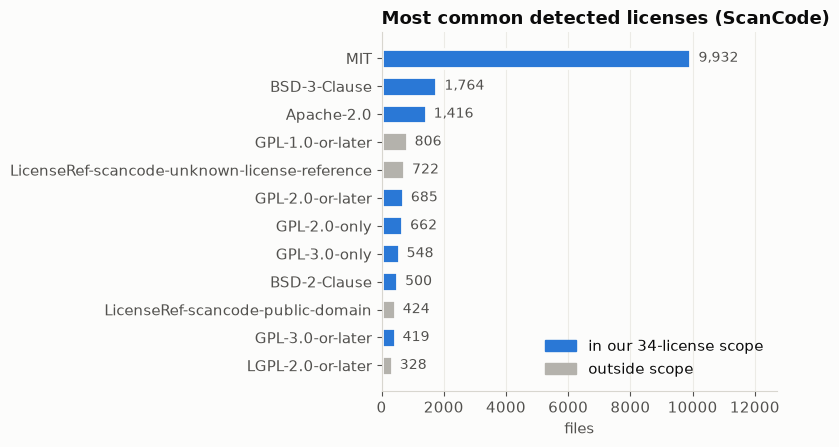

distinct license IDs in sample: 488


In [5]:
lic = sample.licenses.dropna().str.split(";").explode()
top = lic.value_counts().head(12)
kb_ids = {l["spdx_id"] for l in kb}
def in_kb(x):
    for s in ("-only", "-or-later", "+"):
        x = x.removesuffix(s)
    return x in kb_ids
fig, ax = plt.subplots(figsize=(8, 4.6))
hbar(ax, list(top.index), top.values, [BLUE if in_kb(i) else GRAY for i in top.index])
ax.set_title("Most common detected licenses (ScanCode)")
ax.set_xlabel("files")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="in our 34-license scope"), Patch(color=GRAY, label="outside scope")],
          loc="lower right", frameon=False)
save(fig, "02_top_licenses")
print(f"distinct license IDs in sample: {lic.nunique()}")

**Insight:** MIT dominates (≈70% of in-scope files); a long tail of 488 IDs. Recommendations must not simply default to MIT — the subtle copyleft cases matter.

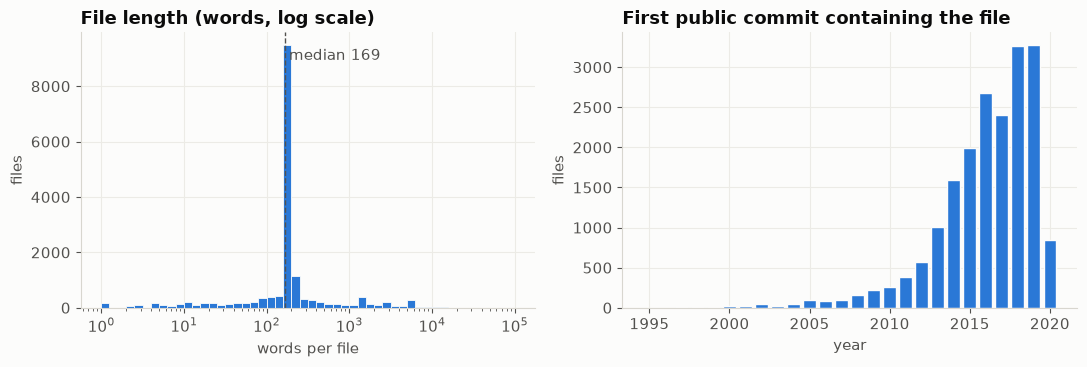

median words 169; median year 2017; since 2015: 76%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
words = sample.word_count[sample.word_count > 0]
bins = [10 ** (i / 10) for i in range(0, 51)]
axes[0].hist(words, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
axes[0].set_xscale("log")
axes[0].set_title("File length (words, log scale)")
axes[0].set_xlabel("words per file"); axes[0].set_ylabel("files")
axes[0].axvline(words.median(), color=INK2, linestyle="--", linewidth=1)
axes[0].text(words.median() * 1.1, axes[0].get_ylim()[1] * 0.9, f"median {words.median():.0f}", color=INK2)

years = pd.to_datetime(sample.earliest_ts, unit="s", errors="coerce").dt.year
years = years[(years >= 1995) & (years <= 2021)]
yc = years.value_counts().sort_index()
axes[1].bar(yc.index, yc.values, color=BLUE, edgecolor=SURFACE, linewidth=1)
axes[1].set_title("First public commit containing the file")
axes[1].set_xlabel("year"); axes[1].set_ylabel("files")
save(fig, "03_length_and_year")
print(f"median words {words.median():.0f}; median year {years.median():.0f}; since 2015: {(years >= 2015).mean():.0%}")

In [7]:
scores = detected.max_score
print(f"ScanCode confidence on detected files: mean {scores.mean():.1f}, score = 100: {(scores == 100).mean():.1%}")
print(f"text formats: {sample.mime_type.str.startswith('text/').mean():.1%} (text/plain {(sample.mime_type == 'text/plain').mean():.1%})")
print("most common file names:", sample.filenames.str.split(';').str[0].str.upper().value_counts().head(5).to_dict())

ScanCode confidence on detected files: mean 99.1, score = 100: 87.9%
text formats: 97.9% (text/plain 84.1%)
most common file names: {'LICENSE': 9897, 'LICENSE.TXT': 1508, 'COPYRIGHT': 1142, 'LICENSE.MD': 1015, 'LICENSE.HTML': 866}


## 5. EDA — License knowledge base & clauses

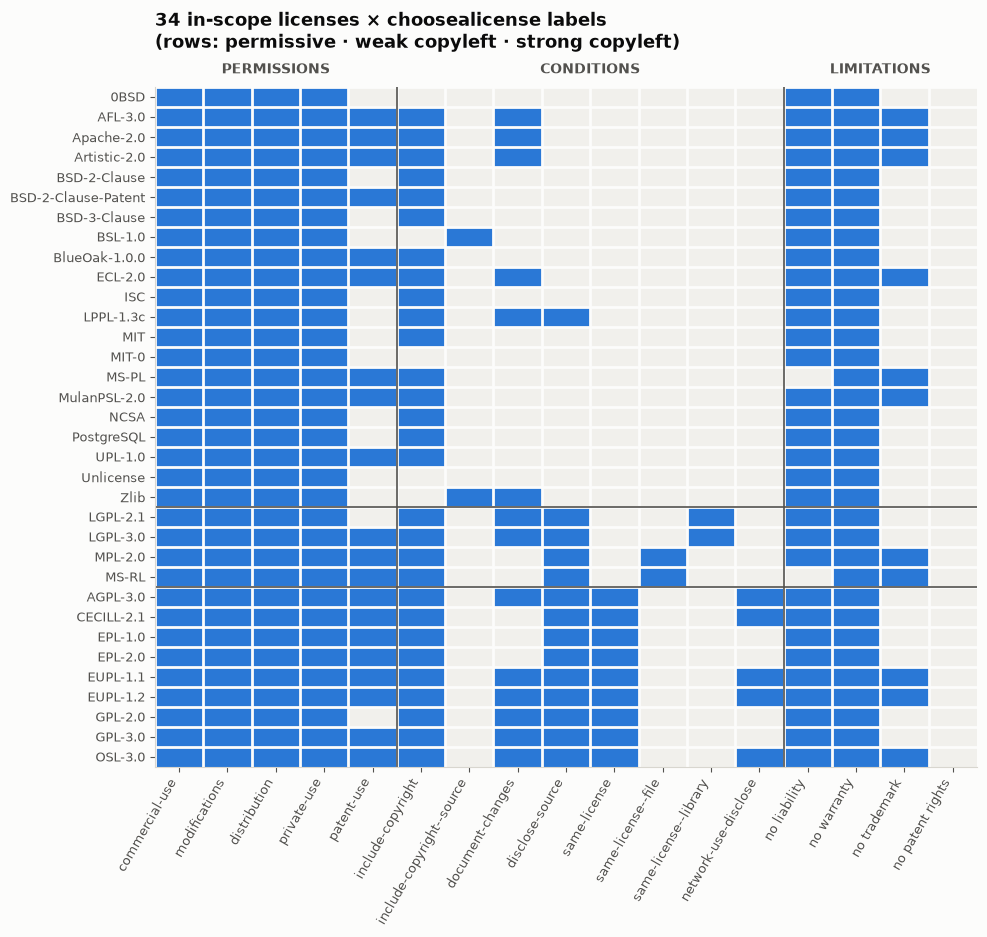

Counter({'none': 21, 'whole_work': 9, 'file_or_library': 4})


In [8]:
from build_scenarios import copyleft
from licensewise.clauses import clauses

labels = [("permissions", x) for x in ["commercial-use", "modifications", "distribution", "private-use", "patent-use"]] + \
         [("conditions", x) for x in ["include-copyright", "include-copyright--source", "document-changes", "disclose-source",
                                      "same-license", "same-license--file", "same-license--library", "network-use-disclose"]] + \
         [("limitations", x) for x in ["liability", "warranty", "trademark-use", "patent-use"]]
rank = {"none": 0, "file_or_library": 1, "whole_work": 2}
rows = sorted(kb, key=lambda l: (rank[copyleft(l)], l["spdx_id"]))
matrix = [[1 if lab in l[cat] else 0 for cat, lab in labels] for l in rows]
fig, ax = plt.subplots(figsize=(10, 9.5))
ax.imshow(matrix, cmap=mcolors.ListedColormap(["#f1f0ec", BLUE]), aspect="auto")
xt = [f"no {lab.replace('-use', '') if lab != 'patent-use' else 'patent rights'}" if cat == "limitations" else lab for cat, lab in labels]
ax.set_xticks(range(len(labels)), xt, rotation=60, ha="right", fontsize=9)
for x0, x1, name in [(0, 4, "PERMISSIONS"), (5, 12, "CONDITIONS"), (13, 16, "LIMITATIONS")]:
    ax.text((x0 + x1) / 2, -1.0, name, ha="center", va="bottom", fontsize=10, fontweight="bold", color=INK2)
ax.set_yticks(range(len(rows)), [l["spdx_id"] for l in rows], fontsize=9)
ax.set_xticks([x - 0.5 for x in range(len(labels))], minor=True)
ax.set_yticks([y - 0.5 for y in range(len(rows))], minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2); ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for x in (4.5, 12.5):
    ax.axvline(x, color=INK2, linewidth=1.2)
for y, name in [(20.5, None), (24.5, None)]:
    ax.axhline(y, color=INK2, linewidth=1.2)
ax.set_title("34 in-scope licenses × choosealicense labels\n(rows: permissive · weak copyleft · strong copyleft)", pad=28)
save(fig, "04_kb_labels_heatmap")
print(Counter(copyleft(l) for l in kb))

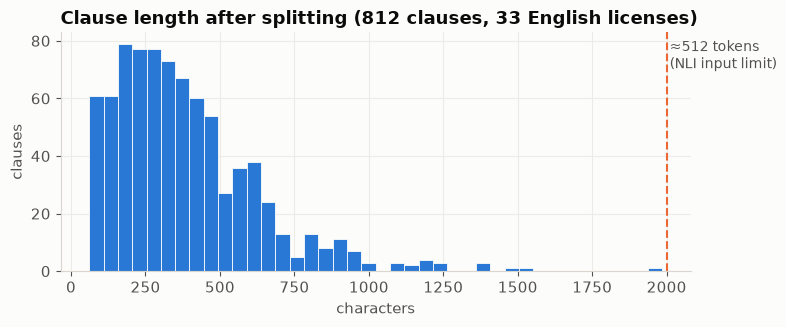

median 328 chars, max 1985


In [9]:
lens = [len(c) for l in kb if l["language"] == "en" for c in clauses(l["text"])]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(lens, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(2000, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(2010, ax.get_ylim()[1] * 0.85, "≈512 tokens\n(NLI input limit)", color=INK2, fontsize=10)
ax.set_title(f"Clause length after splitting ({len(lens)} clauses, 33 English licenses)")
ax.set_xlabel("characters"); ax.set_ylabel("clauses")
save(fig, "05_clause_lengths")
print(f"median {st.median(lens):.0f} chars, max {max(lens)}")

**Insight:** every clause fits the NLI model's 512-token window, so the verifier sees the whole clause — no truncation.

## 6. Test data for evaluation

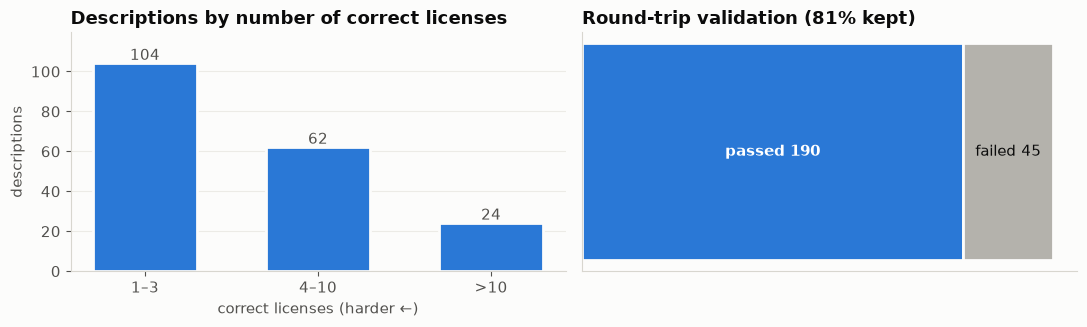

77 profiles · 235 descriptions · 190 valid · 70 profiles covered
example: Solo startup founder — I'm building a compact CLI tool to help simplify local data backups for small teams. I want anyone to feel free to tweak the logic or fix bugs without having to log their changes in a changelog or mark their edits specifically. My main priority is keeping the contribution process lightweight so developers can just push code without extra documentation overhead.


In [10]:
profiles = [json.loads(l) for l in open(DATA / "scenarios" / "profiles.jsonl")]
descs = [json.loads(l) for l in open(DATA / "scenarios" / "descriptions.jsonl")]
valid = [d for d in descs if d["valid"]]
bucket = lambda n: "1–3" if n <= 3 else "4–10" if n <= 10 else ">10"
bc = Counter(bucket(len(d["gold"])) for d in valid)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
b = ["1–3", "4–10", ">10"]
axes[0].bar(b, [bc[x] for x in b], color=BLUE, width=0.6, edgecolor=SURFACE, linewidth=2)
for i, x in enumerate(b):
    axes[0].text(i, bc[x], f"{bc[x]}", ha="center", va="bottom", color=INK2)
axes[0].set_ylim(0, max(bc.values()) * 1.15); axes[0].set_title("Descriptions by number of correct licenses")
axes[0].set_xlabel("correct licenses (harder ←)"); axes[0].set_ylabel("descriptions"); axes[0].grid(axis="x", visible=False)
passed = len(valid); failed = len(descs) - passed
axes[1].barh(["round trip"], [passed], color=BLUE, height=0.5, edgecolor=SURFACE, linewidth=2)
axes[1].barh(["round trip"], [failed], left=[passed], color=GRAY, height=0.5, edgecolor=SURFACE, linewidth=2)
axes[1].text(passed / 2, 0, f"passed {passed}", ha="center", va="center", color="white", fontweight="bold")
axes[1].text(passed + failed / 2, 0, f"failed {failed}", ha="center", va="center", color=INK)
axes[1].set_title(f"Round-trip validation ({passed / len(descs):.0%} kept)"); axes[1].grid(visible=False)
axes[1].set_xticks([]); axes[1].set_yticks([])
save(fig, "06_test_descriptions")
print(f"{len(profiles)} profiles · {len(descs)} descriptions · {passed} valid · {len({d['profile_id'] for d in valid})} profiles covered")
print("example:", valid[0]["persona"], "—", valid[0]["text"])

In [11]:
pairs = [json.loads(l) for l in open(DATA / "nli" / "pairs.jsonl")]
print(f"NLI test set: {len(pairs)} clause–claim pairs ·", dict(Counter(p['nli_label'] for p in pairs)))
pd.DataFrame(pairs)[["license", "label", "premise", "hypothesis", "nli_label"]].sample(4, random_state=1)

NLI test set: 729 clause–claim pairs · {'entailment': 243, 'contradiction': 243, 'neutral': 243}


,license,label,premise,hypothesis,nli_label
248,EPL-2.0,modifications,"""Modified Works"" shall mean any work in Source...",You are allowed to modify the software.,entailment
674,PostgreSQL,distribution,"PostgreSQL License Copyright (c) [year], [full...",Modifications to the library must be released ...,neutral
159,BSD-3-Clause,distribution,"BSD 3-Clause License Copyright (c) [year], [fu...",You are not allowed to distribute copies of th...,contradiction
355,GPL-2.0,disclose-source,"For example, if you distribute copies of such ...","When you distribute the software, you must mak...",entailment


## 7. Models
| Model | Role | Why |
|---|---|---|
| `openai/gpt-oss-120b` (Groq) | Stage 1 recommend · Stage 2 explain | Open-weight, strong reasoning, strict JSON schema output |
| `MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli` (local) | NLI verifier | Best on our test set (section 8) |
| `FacebookAI/roberta-large-mnli` | Baseline verifier | Widely used NLI baseline |
| `qwen/qwen3.8-27b` · `openai/gpt-oss-20b` | Write · check test descriptions | Different from the pipeline model → less evaluation bias |

## 8. Evaluation — NLI verifier

In [12]:
from run_nli import human_labels, metrics, MODELS
auto = {p["pair_id"]: p["nli_label"] for p in pairs}
human = human_labels()
res = {}
for short in MODELS:
    pred = {json.loads(l)["pair_id"]: json.loads(l)["predicted"] for l in open(DATA / "nli" / f"predictions_{short}.jsonl")}
    ids = sorted(human)
    res[short] = {"auto": metrics([auto[i] for i in auto], [pred[i] for i in auto]),
                  "human": metrics([human[i] for i in ids], [pred[i] for i in ids]), "pred": pred}
table = pd.DataFrame({m: {"accuracy": r["human"]["accuracy"], "macro-F1": r["human"]["macro_f1"],
                          "entailment precision": r["human"]["per_class"]["entailment"]["precision"],
                          "entailment recall": r["human"]["per_class"]["entailment"]["recall"],
                          "contradiction F1": r["human"]["per_class"]["contradiction"]["f1"]}
                      for m, r in res.items()})
print(f"hand-labelled pairs: {len(human)} · auto labels correct: {sum(human[i] == auto[i] for i in human) / len(human):.1%}")
table

hand-labelled pairs: 146 · auto labels correct: 97.9%


,roberta-large-mnli,deberta-v3-large-nli
accuracy,0.733,0.815
macro-F1,0.729,0.816
entailment precision,0.900,0.944
entailment recall,0.551,0.694
contradiction F1,0.849,0.889


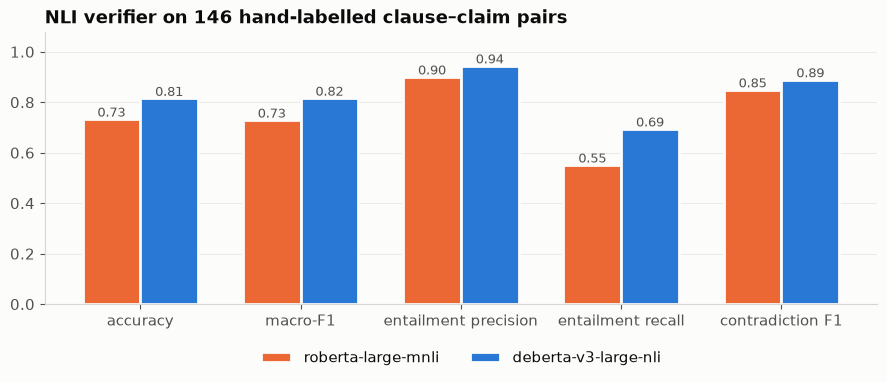

In [13]:
import numpy as np
fig, ax = plt.subplots(figsize=(9, 4))
metric_names = list(table.index)
x = np.arange(len(metric_names)); w = 0.36
for k, (model, color) in enumerate([("roberta-large-mnli", ORANGE), ("deberta-v3-large-nli", BLUE)]):
    vals = table[model].values
    ax.bar(x + (k - 0.5) * w, vals, w, color=color, label=model, edgecolor=SURFACE, linewidth=2)
    for xi, v in zip(x, vals):
        ax.text(xi + (k - 0.5) * w, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, metric_names); ax.set_ylim(0, 1.08); ax.grid(axis="x", visible=False)
ax.set_title(f"NLI verifier on {len(human)} hand-labelled clause–claim pairs")
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
save(fig, "07_nli_models")

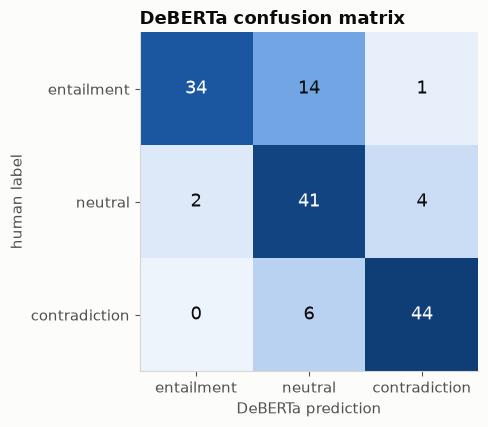

In [14]:
cm = res["deberta-v3-large-nli"]["human"]["confusion"]
order = ["entailment", "neutral", "contradiction"]
M = np.array([[cm[g][p] for p in order] for g in order])
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.imshow(M, cmap=SEQ)
ax.set_xticks(range(3), order); ax.set_yticks(range(3), order); ax.grid(visible=False)
ax.set_xlabel("DeBERTa prediction"); ax.set_ylabel("human label")
for i in range(3):
    for j in range(3):
        ax.text(j, i, M[i, j], ha="center", va="center", fontsize=13,
                color="white" if M[i, j] > M.max() * 0.55 else INK)
ax.set_title("DeBERTa confusion matrix")
save(fig, "08_nli_confusion")

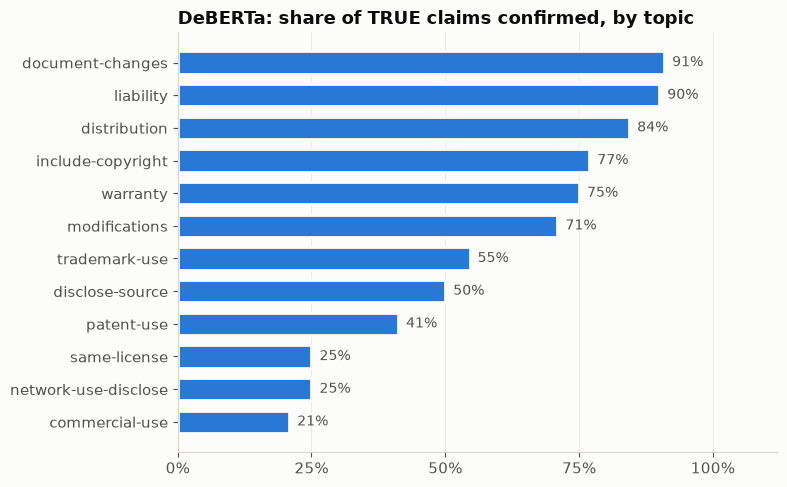

inter-annotator agreement: 0.925 kappa: 0.886


In [15]:
# Where the verifier misses true claims: entailment recall per license label (auto labels, 729 pairs)
pred = res["deberta-v3-large-nli"]["pred"]
by = {}
for p in pairs:
    if p["nli_label"] == "entailment":
        a, n = by.get(p["label"], (0, 0)); by[p["label"]] = (a + (pred[p["pair_id"]] == "entailment"), n + 1)
rec = pd.Series({k: a / n for k, (a, n) in by.items() if n >= 4}).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
hbar(ax, list(rec.index[::-1]), list(rec.values[::-1]), BLUE, fmt="{:.0%}")
ax.set_xlim(0, 1.12); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("DeBERTa: share of TRUE claims confirmed, by topic")
save(fig, "09_nli_recall_by_label")
agreement = json.loads((DATA / "nli" / "agreement_results.json").read_text())
print("inter-annotator agreement:", agreement["overall"]["agreement"], "kappa:", agreement["overall"]["kappa"])

**Strength:** when DeBERTa says *verified* it is right ~94% of the time. **Weakness:** copyleft and 'commercial use' claims need inference beyond the clause wording, so many true claims stay *unverified*.

## 9. Evaluation — Stage 1 recommendation

In [16]:
from eval_stage1 import score, load_jsonl, RESULTS, PROFILES
results = load_jsonl(RESULTS)
prof = {p["profile_id"]: p for p in load_jsonl(PROFILES)}
covered = {r["profile_id"] for r in results}
print(f"evaluated: {len(results)} of {len(valid)} validated descriptions, covering {len(covered)} of "
      f"{len({d['profile_id'] for d in valid})} profiles (every profile at least once; the rest were not run "
      "because of Groq's free-tier limit of 200k tokens/day)")
summary = score(results, prof) if results else {}
pd.DataFrame({k: v for k, v in summary.items() if k != "violation_rate_by_constraint"}).T

evaluated: 104 of 190 validated descriptions, covering 70 of 70 profiles (every profile at least once; the rest were not run because of Groq's free-tier limit of 200k tokens/day)


,n,hit@1,hit@3,precision@3
all,104.0,0.558,0.740,0.548
gold >10,22.0,0.909,1.000,0.879
gold 1-3,47.0,0.404,0.596,0.418
gold 4-10,35.0,0.543,0.771,0.514


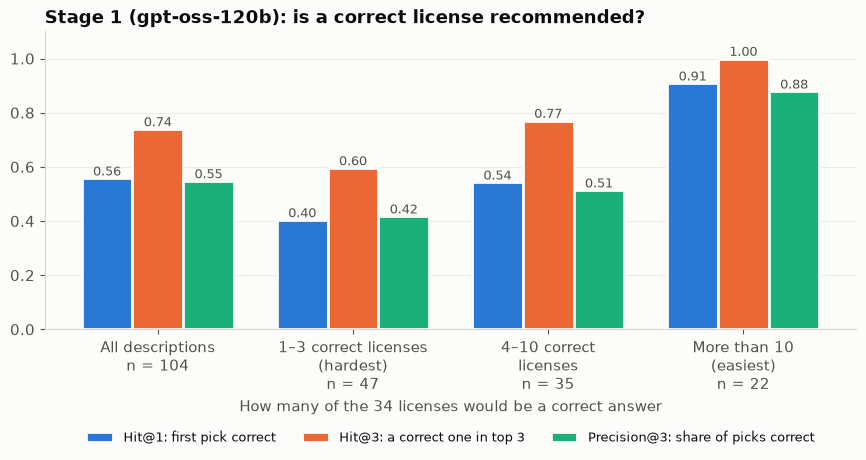

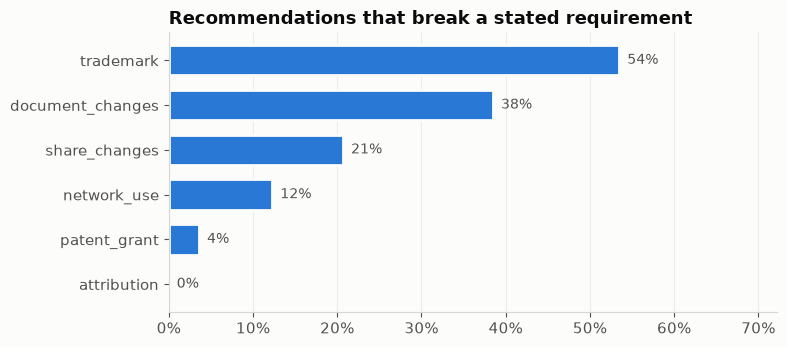

In [17]:
if summary:
    groups = [g for g in ["all", "gold 1-3", "gold 4-10", "gold >10"] if g in summary]
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(groups)); w = 0.26
    names = {"hit@1": "Hit@1: first pick correct", "hit@3": "Hit@3: a correct one in top 3", "precision@3": "Precision@3: share of picks correct"}
    for k, (m, color) in enumerate([("hit@1", BLUE), ("hit@3", ORANGE), ("precision@3", AQUA)]):
        vals = [summary[g][m] for g in groups]
        ax.bar(x + (k - 1) * w, vals, w, color=color, label=names[m], edgecolor=SURFACE, linewidth=2)
        for xi, v in zip(x, vals):
            ax.text(xi + (k - 1) * w, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
    nice = {"all": "All descriptions", "gold 1-3": "1–3 correct licenses\n(hardest)", "gold 4-10": "4–10 correct\nlicenses", "gold >10": "More than 10\n(easiest)"}
    ax.set_xticks(x, [f"{nice[g]}\nn = {summary[g]['n']}" for g in groups]); ax.set_ylim(0, 1.1); ax.grid(axis="x", visible=False)
    ax.set_xlabel("How many of the 34 licenses would be a correct answer")
    ax.set_title("Stage 1 (gpt-oss-120b): is a correct license recommended?")
    ax.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.3), fontsize=9.5)
    save(fig, "10_stage1_hits")

    vr = pd.Series(summary["violation_rate_by_constraint"]).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    hbar(ax, list(vr.index), list(vr.values), BLUE, fmt="{:.0%}")
    ax.set_xlim(0, max(vr.max() * 1.35, 0.1)); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title("Recommendations that break a stated requirement")
    save(fig, "11_stage1_violations")

## 10. Pipeline demo

Saved end-to-end runs (`scripts/recommend.py`). Set `RUN_LIVE = True` to run a new one (needs `GROQ_API_KEY` in `.env`; 1–5 min on the free tier).

In [18]:
def show(result):
    print("Requirements:", [r["text"] for r in result["requirements"]])
    for c in result["conflicts"]:
        print(f"  ! {c['dependency']} ({c['dependency_license']}): {c['issue']}")
    for rec in result["recommendations"]:
        print(f"\n{rec['rank']}. {rec['spdx_id']} — {rec['reason']}")
        for c in rec["claims"]:
            print(f"   [{c['status']:12}] {c['text']}")
    print(f"\n{result['disclaimer']}  ({result['timings']['total_s']} s)")

for name in ["demo_saas", "demo_manifest"]:
    print(f"===== {name} =====")
    show(json.loads((DATA / "runs" / f"{name}.json").read_text()))

===== demo_saas =====
Requirements: ['Improvements, including those made by companies running it as a hosted SaaS, should be contributed back to the community.']

1. AGPL-3.0 — Provides strong network copyleft ensuring that any modifications used to offer a SaaS must be released back to the community.
   [unverified  ] All of your improvements must be released under the AGPL for anyone who receives the software.
   [unverified  ] If you run the program as a SaaS, you must let remote users download the source of your version at no cost.
   [verified    ] When you distribute compiled binaries, you must also make the source code freely available in the same place.

2. GPL-3.0 — Strong copyleft that requires source code distribution of derived works, encouraging contributions when the library is redistributed.
   [unverified  ] If you distribute a modified version, you must license the whole work under the GPL so anyone receiving it gets the same rights.
   [verified    ] When you share a 

In [19]:
RUN_LIVE = False
if RUN_LIVE:
    from licensewise import pipeline
    show(pipeline.recommend("A CLI tool for researchers; anyone can reuse it, even in closed-source products, but they must credit us."))